# Case iFood — Part 2  
## Família de Boosting: LightGBM, XGBoost e CatBoost

Neste notebook vamos:
- carregar o histórico da Parte 1
- apresentar modelos da família de boosting
- comparar os resultados com threshold 0.5 e melhor threshold de negócio
- atualizar o histórico simplificado

In [2]:

# Se necessário:
# !pip install lightgbm xgboost catboost pyarrow

In [3]:

import os
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

SEED = 42
ARTIFACTS_DIR = "artifacts"
HISTORY_PARQUET = os.path.join(ARTIFACTS_DIR, "experiments_history.parquet")
HISTORY_CSV = os.path.join(ARTIFACTS_DIR, "experiments_history.csv")
TARGET = "Response"

## 15. Carregamento dos dados e do histórico

In [4]:

Xtrain_raw = pd.read_parquet(os.path.join(ARTIFACTS_DIR, "Xtrain_raw.parquet"))
Xtest_raw = pd.read_parquet(os.path.join(ARTIFACTS_DIR, "Xtest_raw.parquet"))
ytrain = pd.read_parquet(os.path.join(ARTIFACTS_DIR, "ytrain.parquet"))[TARGET]
ytest = pd.read_parquet(os.path.join(ARTIFACTS_DIR, "ytest.parquet"))[TARGET]

if os.path.exists(HISTORY_PARQUET):
    try:
        history = pd.read_parquet(HISTORY_PARQUET)
    except Exception:
        history = pd.read_csv(HISTORY_CSV)
else:
    history = pd.read_csv(HISTORY_CSV)

history.tail()

,run_date,notebook_part,model_name,experiment_type,threshold_label,threshold,precision,recall,f1,auc
7,2026-03-12 00:19:45,part1,logistic_regression,baseline,best_business_threshold,0.73,0.631579,0.537313,0.580645,0.899440
8,2026-03-12 00:19:45,part1,decision_tree,baseline,default_0.5,0.50,0.463415,0.283582,0.351852,0.792964
9,2026-03-12 00:19:45,part1,decision_tree,baseline,best_business_threshold,0.62,0.545455,0.268657,0.360000,0.792964
10,2026-03-12 00:19:45,part1,random_forest,baseline,default_0.5,0.50,0.666667,0.447761,0.535714,0.892976
11,2026-03-12 00:19:45,part1,random_forest,baseline,best_business_threshold,0.46,0.625000,0.522388,0.569106,0.892976


## 16. Preparação dos dados para boosting

### LightGBM e XGBoost
Neste notebook vamos usar a abordagem mais didática:
- imputação
- One-Hot Encoding para categorias
- sem normalização

### CatBoost
O CatBoost consegue lidar muito bem com variáveis categóricas, mas para manter a comparação simples nesta etapa,
vamos usar a mesma base transformada para todos os modelos.

In [5]:

cat_cols = Xtrain_raw.select_dtypes(include=["object", "string", "category", "boolean"]).columns.tolist()
num_cols = [c for c in Xtrain_raw.columns if c not in cat_cols]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols)
])

In [6]:

def metricas_classificacao(y_true, y_proba, threshold=0.5):
    y_pred = (y_proba >= threshold).astype(int)
    return {
        "threshold": threshold,
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "auc": roc_auc_score(y_true, y_proba)
    }

def escolher_melhor_threshold_negocio(y_true, y_proba, recall_min=0.50, thresholds=None):
    if thresholds is None:
        thresholds = np.round(np.arange(0.30, 0.81, 0.01), 2)
    resultados = [metricas_classificacao(y_true, y_proba, t) for t in thresholds]
    df_thr = pd.DataFrame(resultados)
    candidatos = df_thr[df_thr["recall"] >= recall_min].copy()
    if len(candidatos) == 0:
        melhor = df_thr.sort_values(["precision", "recall"], ascending=False).iloc[0]
    else:
        melhor = candidatos.sort_values(["precision", "recall", "f1"], ascending=False).iloc[0]
    return df_thr, melhor

def registrar_modelo(hist_df, notebook_part, model_name, experiment_type, metricas_default, metricas_best):
    linhas = []
    for label, m in [("default_0.5", metricas_default), ("best_business_threshold", metricas_best)]:
        linhas.append({
            "run_date": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
            "notebook_part": notebook_part,
            "model_name": model_name,
            "experiment_type": experiment_type,
            "threshold_label": label,
            "threshold": float(m["threshold"]),
            "precision": float(m["precision"]),
            "recall": float(m["recall"]),
            "f1": float(m["f1"]),
            "auc": float(m["auc"])
        })
    return pd.concat([hist_df, pd.DataFrame(linhas)], ignore_index=True)

def save_history(df_hist):
    try:
        df_hist.to_parquet(HISTORY_PARQUET, index=False)
    except Exception as e:
        print(f"Parquet indisponível ({e}).")
    df_hist.to_csv(HISTORY_CSV, index=False)

## 17. LightGBM

### Conceito
LightGBM é um algoritmo de boosting baseado em árvores, projetado para ser rápido e eficiente.

### Hiperparâmetros principais
- `n_estimators`: quantidade de árvores
- `learning_rate`: tamanho do passo
- `num_leaves`: complexidade das árvores
- `max_depth`: profundidade máxima

In [7]:

lgbm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        random_state=SEED
    ))
])

lgbm_model.fit(Xtrain_raw, ytrain)
lgbm_proba = lgbm_model.predict_proba(Xtest_raw)[:, 1]

lgbm_default = metricas_classificacao(ytest, lgbm_proba, threshold=0.5)
lgbm_thr_df, lgbm_best = escolher_melhor_threshold_negocio(ytest, lgbm_proba)
pd.DataFrame([lgbm_default, lgbm_best], index=["threshold_0.5", "best_business_threshold"])

[LightGBM] [Info] Number of positive: 267, number of negative: 1525
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001400 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2102
[LightGBM] [Info] Number of data points in the train set: 1792, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.148996 -> initscore=-1.742501
[LightGBM] [Info] Start training from score -1.742501


c:\MD\virtual_envs\fiap_ml_env\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,threshold,precision,recall,f1,auc
threshold_0.5,0.50,0.750000,0.402985,0.524272,0.893583
best_business_threshold,0.54,0.794118,0.402985,0.534653,0.893583


## 18. XGBoost

### Conceito
XGBoost também é um método de boosting com árvores, muito conhecido por sua robustez em problemas tabulares.

### Hiperparâmetros principais
- `n_estimators`
- `learning_rate`
- `max_depth`
- `subsample`
- `colsample_bytree`

In [8]:

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=SEED
    ))
])

xgb_model.fit(Xtrain_raw, ytrain)
xgb_proba = xgb_model.predict_proba(Xtest_raw)[:, 1]

xgb_default = metricas_classificacao(ytest, xgb_proba, threshold=0.5)
xgb_thr_df, xgb_best = escolher_melhor_threshold_negocio(ytest, xgb_proba)
pd.DataFrame([xgb_default, xgb_best], index=["threshold_0.5", "best_business_threshold"])

,threshold,precision,recall,f1,auc
threshold_0.5,0.50,0.675000,0.402985,0.504673,0.915345
best_business_threshold,0.38,0.698113,0.552239,0.616667,0.915345


## 19. CatBoost

### Conceito
CatBoost é um algoritmo de boosting muito forte para dados tabulares e tem bom tratamento para categorias.

### Hiperparâmetros principais
- `iterations`
- `learning_rate`
- `depth`
- `l2_leaf_reg`

In [9]:

cat_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", CatBoostClassifier(
        iterations=300,
        learning_rate=0.05,
        depth=6,
        verbose=0,
        random_seed=SEED
    ))
])

cat_model.fit(Xtrain_raw, ytrain)
cat_proba = cat_model.predict_proba(Xtest_raw)[:, 1]

cat_default = metricas_classificacao(ytest, cat_proba, threshold=0.5)
cat_thr_df, cat_best = escolher_melhor_threshold_negocio(ytest, cat_proba)
pd.DataFrame([cat_default, cat_best], index=["threshold_0.5", "best_business_threshold"])

,threshold,precision,recall,f1,auc
threshold_0.5,0.50,0.843750,0.402985,0.545455,0.912211
best_business_threshold,0.35,0.723404,0.507463,0.596491,0.912211


## 20. Comparação dos modelos de boosting

In [10]:

boost_compare = pd.DataFrame([
    {"model_name": "lightgbm", **lgbm_default},
    {"model_name": "xgboost", **xgb_default},
    {"model_name": "catboost", **cat_default},
]).sort_values(["precision", "recall"], ascending=False)

boost_compare

,model_name,threshold,precision,recall,f1,auc
2,catboost,0.5,0.84375,0.402985,0.545455,0.912211
0,lightgbm,0.5,0.75000,0.402985,0.524272,0.893583
1,xgboost,0.5,0.67500,0.402985,0.504673,0.915345


## 21. Precision e Recall vs Threshold

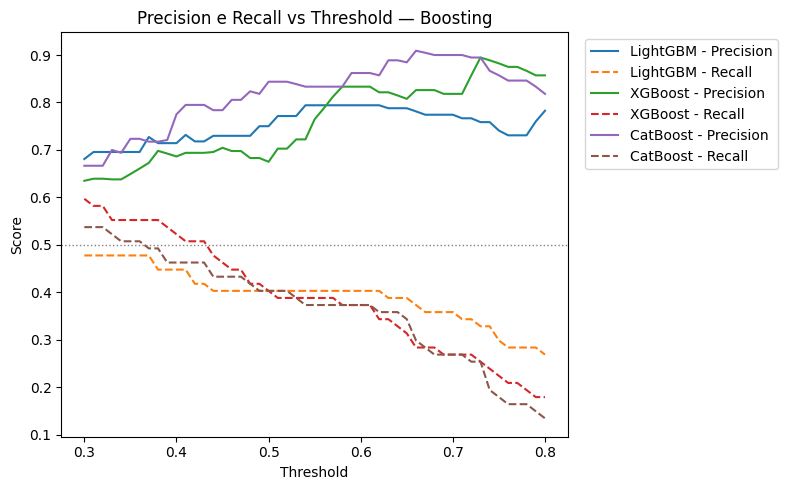

In [11]:

plt.figure(figsize=(8,5))
for nome, df_thr in [
    ("LightGBM", lgbm_thr_df),
    ("XGBoost", xgb_thr_df),
    ("CatBoost", cat_thr_df)
]:
    plt.plot(df_thr["threshold"], df_thr["precision"], label=f"{nome} - Precision")
    plt.plot(df_thr["threshold"], df_thr["recall"], linestyle="--", label=f"{nome} - Recall")

plt.axhline(0.50, color="gray", linestyle=":", linewidth=1)
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision e Recall vs Threshold — Boosting")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 22. Atualização do histórico simplificado

In [12]:

history = registrar_modelo(history, "part2", "lightgbm", "baseline_boosting", lgbm_default, lgbm_best)
history = registrar_modelo(history, "part2", "xgboost", "baseline_boosting", xgb_default, xgb_best)
history = registrar_modelo(history, "part2", "catboost", "baseline_boosting", cat_default, cat_best)

save_history(history)
history.tail(6)

,run_date,notebook_part,model_name,experiment_type,threshold_label,threshold,precision,recall,f1,auc
12,2026-03-12 00:23:52,part2,lightgbm,baseline_boosting,default_0.5,0.50,0.750000,0.402985,0.524272,0.893583
13,2026-03-12 00:23:52,part2,lightgbm,baseline_boosting,best_business_threshold,0.54,0.794118,0.402985,0.534653,0.893583
14,2026-03-12 00:23:52,part2,xgboost,baseline_boosting,default_0.5,0.50,0.675000,0.402985,0.504673,0.915345
15,2026-03-12 00:23:52,part2,xgboost,baseline_boosting,best_business_threshold,0.38,0.698113,0.552239,0.616667,0.915345
16,2026-03-12 00:23:52,part2,catboost,baseline_boosting,default_0.5,0.50,0.843750,0.402985,0.545455,0.912211
17,2026-03-12 00:23:52,part2,catboost,baseline_boosting,best_business_threshold,0.35,0.723404,0.507463,0.596491,0.912211


## 23. Leaderboard parcial

In [13]:

leaderboard = (
    history.sort_values(["precision", "recall", "f1"], ascending=False)
    .reset_index(drop=True)
)

leaderboard.head(15)

,run_date,notebook_part,model_name,experiment_type,threshold_label,threshold,precision,recall,f1,auc
0,2026-03-12 00:23:52,part2,catboost,baseline_boosting,default_0.5,0.50,0.843750,0.402985,0.545455,0.912211
1,2026-03-12 00:23:52,part2,lightgbm,baseline_boosting,best_business_threshold,0.54,0.794118,0.402985,0.534653,0.893583
2,2026-03-12 00:23:52,part2,lightgbm,baseline_boosting,default_0.5,0.50,0.750000,0.402985,0.524272,0.893583
3,2026-03-12 00:23:52,part2,catboost,baseline_boosting,best_business_threshold,0.35,0.723404,0.507463,0.596491,0.912211
4,2026-03-12 00:23:52,part2,xgboost,baseline_boosting,best_business_threshold,0.38,0.698113,0.552239,0.616667,0.915345
5,2026-03-12 00:23:52,part2,xgboost,baseline_boosting,default_0.5,0.50,0.675000,0.402985,0.504673,0.915345
6,2026-03-12 00:19:35,part1,random_forest,baseline,default_0.5,0.50,0.666667,0.447761,0.535714,0.892976
7,2026-03-12 00:19:45,part1,random_forest,baseline,default_0.5,0.50,0.666667,0.447761,0.535714,0.892976
8,2026-03-12 00:19:35,part1,logistic_regression,baseline,best_business_threshold,0.73,0.631579,0.537313,0.580645,0.899440
9,2026-03-12 00:19:45,part1,logistic_regression,baseline,best_business_threshold,0.73,0.631579,0.537313,0.580645,0.899440


## 24. Fechamento
Ao final do Part 2, já conhecemos:
- baselines clássicos
- família de boosting
- efeito do threshold sobre precision e recall

No **Part 3**, faremos:
- tuning manual de Decision Tree
- Grid Search
- Randomized Search
- Bayesian Optimization
- comparação final com foco em precision e recall aceitável